# Lab 3 — Descriptive Statistics Assignment: Gym Membership Dataset

**School of Computer Science and Engineering (SOCSE) — RV University**

**Name:** Francis Reuben R  **Roll No.:** 1RUA25CSE0168  **Section:** G

---

## Instructions

- This is a follow-up to Lab 3 (descriptive statistics on the student survey dataset). The same
  concepts — central tendency, dispersion, distribution shape, and visualization — are applied here
  to a **new dataset** describing gym members, so you can practice choosing the right
  statistic rather than remembering the answer from Lab 3.
-
- Every question below has an empty code cell (marked `# TODO`) for your solution, and most also   have a markdown cell marked **Your answer:** for a short written interpretation. Write your
  interpretation in your own words — a correct number with no explanation will not receive full  marks for questions that ask you to interpret.
- Run your notebook **top to bottom** (Kernel → Restart & Run All) before submitting, and make sure
  it completes with no errors.
-

### Learning objectives
By the end of this assignment you should be able to: compute and correctly choose between mean,
median, and mode; compute and interpret variance, standard deviation, and IQR; use skewness and
kurtosis to identify non-normal distributions; and build/interpret histograms, box plots, and scatter plots to support (or challenge) what the summary statistics suggest.


In [1]:
%matplotlib inline
# --- Core libraries used throughout the notebook (provided — no changes needed) ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RANDOM_SEED = 7
np.random.seed(RANDOM_SEED)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

print("Libraries loaded. Random seed set to", RANDOM_SEED)

Libraries loaded. Random seed set to 7


## Part 1 — The Dataset (provided, do not modify)

This dataset simulates **150 gym members**, with the same design idea as Lab 3: each numeric
feature is deliberately shaped differently, so no single statistic works well for all of them.

| Feature | Real-world meaning | Intended shape |
|---|---|---|
| `workout_duration_minutes` | Average length of a workout session | *(shape not disclosed — see Q7/Q8)* |
| `monthly_membership_fee_inr` | Monthly membership fee paid (₹) | *(shape not disclosed — see Q7/Q8)* |
| `attendance_percentage` | % of scheduled sessions actually attended | *(shape not disclosed — see Q7/Q8)* |
| `weekly_visit_count` | Number of gym visits per week | *(shape not disclosed — see Q7/Q8)* |
| `preferred_workout` | Favorite workout category | categorical |

Unlike Lab 3, the shapes are **not labeled** for you this time — figuring out which feature is
approximately normal, right-skewed, left-skewed, or bimodal (and *proving it* with statistics and
plots) is part of the assignment.

In [2]:
df=pd.read_csv("gym_members_synthetic.csv")
df.head(8)

,member_id,workout_duration_minutes,monthly_membership_fee_inr,attendance_percentage,weekly_visit_count,preferred_workout
0,M001,69.7,1690.0,71.7,1.3,Cardio
1,M002,81.0,2450.0,86.2,2.2,Weights
2,M003,62.6,2190.0,89.0,5.1,CrossFit
3,M004,65.7,3170.0,79.6,5.4,Cardio
4,M005,49.3,1050.0,80.7,1.5,Weights
5,M006,39.1,1180.0,88.0,5.0,Weights
6,M007,52.3,800.0,81.3,2.1,Weights
7,M008,73.0,2630.0,82.3,5.5,Yoga


### Q1 (2 marks) — Initial exploration

In the code cell below: display the shape of `df`, the data type of each column (`.dtypes`), the
summary statistics of the numeric columns (`.describe()`), and check whether any values are
missing (`.isna().sum()`).

In [3]:
# Q1: shape, dtypes, describe(), missing-value check
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nSummary of numeric columns:")
display(df.describe())
print("Missing values per column:")
print(df.isna().sum())


Shape: (150, 6)

Data types:
member_id                         str
workout_duration_minutes      float64
monthly_membership_fee_inr    float64
attendance_percentage         float64
weekly_visit_count            float64
preferred_workout                 str
dtype: object

Summary of numeric columns:


,workout_duration_minutes,monthly_membership_fee_inr,attendance_percentage,weekly_visit_count
count,150.000,150.000,150.000,150.000
mean,54.618,2283.067,84.210,3.337
std,11.397,984.837,5.874,1.886
min,27.800,800.000,66.200,0.300
25%,48.050,1515.000,80.175,1.800
50%,54.350,2030.000,85.100,2.400
75%,62.875,2825.000,88.775,5.300
max,81.000,6420.000,94.700,7.100


Missing values per column:
member_id                     0
workout_duration_minutes      0
monthly_membership_fee_inr    0
attendance_percentage         0
weekly_visit_count            0
preferred_workout             0
dtype: int64


## Part 2 — Measures of Central Tendency

Recall from Lab 3: the **mean** uses every value and is efficient but outlier-sensitive; the
**median** only depends on the middle position and is robust to outliers; the **mode** is the most
frequent value and is most meaningful for categorical or discrete data.



In the code cell below, compute the **mean, median, and mode** of each of the four numeric features
in `FEATURES`, and separately the **mode** of `preferred_workout`. Present the four numeric results
as a single small table (a DataFrame is fine).

In [4]:
# Q2: mean, median, mode for each numeric feature; mode of preferred_workout
FEATURES = [
    "workout_duration_minutes",
    "monthly_membership_fee_inr",
    "attendance_percentage",
    "weekly_visit_count",
]

ct = pd.DataFrame({
    "mean": df[FEATURES].mean(),
    "median": df[FEATURES].median(),
    "mode": [df[col].mode().iloc[0] for col in FEATURES],
})
ct["mean_minus_median"] = ct["mean"] - ct["median"]
ct["rel_diff_pct"] = (ct["mean"] - ct["median"]).abs() / ct["median"] * 100
display(ct)

print("Mode of preferred_workout:", df["preferred_workout"].mode().tolist())
print("Counts:")
print(df["preferred_workout"].value_counts())


,mean,median,mode,mean_minus_median,rel_diff_pct
workout_duration_minutes,54.618,54.35,57.8,0.268,0.493
monthly_membership_fee_inr,2283.067,2030.00,1440.0,253.067,12.466
attendance_percentage,84.210,85.10,85.1,-0.890,1.046
weekly_visit_count,3.337,2.40,2.3,0.937,39.028


Mode of preferred_workout: ['Cardio', 'Weights']
Counts:
preferred_workout
Cardio      53
Weights     53
Yoga        28
CrossFit    16
Name: count, dtype: int64


### Q3  — Written interpretation

Looking at your table from Q2: for which numeric feature(s) do the mean and median differ the most
(in relative, not absolute, terms)? What does that gap suggest about the shape of that feature's
distribution, and in which direction would you expect its tail to stretch? You have not plotted
anything yet — base your answer only on the numbers.

**Your answer:**

`weekly_visit_count` has the largest relative gap (mean 3.34 vs median 2.40, about 39%). `monthly_membership_fee_inr` is next (mean 2283 vs median 2030, about 12%). In both cases the mean sits above the median, so from the numbers alone I would expect a longer right tail. `workout_duration_minutes` and `attendance_percentage` have mean and median within about 1%, so those two look roughly balanced.


### Q4 (4 marks) — The outlier effect

Suppose one gym member signs up for a **founder's lifetime membership** and pays a one-time fee of
**₹80,000** that month. In the code cell below: make a **copy** of `df` (do not modify the original
`df`), add this one hypothetical value to `monthly_membership_fee_inr` in the copy, and print the
mean and median of that column **before and after** adding it.

Then, in the markdown cell below, explain in 2–3 sentences why the mean and median reacted
differently, referencing what you know about how each statistic is calculated.

In [5]:
# Q4: add the Rs 80,000 outlier to a COPY, compare mean/median before vs after
col = "monthly_membership_fee_inr"
df_out = df.copy()
fees_after = pd.concat([df_out[col], pd.Series([80000])], ignore_index=True)

print("Before adding Rs 80,000")
print(f"  mean:   {df[col].mean():.2f}")
print(f"  median: {df[col].median():.2f}")
print("After adding Rs 80,000")
print(f"  mean:   {fees_after.mean():.2f}")
print(f"  median: {fees_after.median():.2f}")
print(f"Change in mean:   {fees_after.mean() - df[col].mean():.2f}")
print(f"Change in median: {fees_after.median() - df[col].median():.2f}")
print("Original df still has", len(df), "rows (copy was used).")


Before adding Rs 80,000
  mean:   2283.07
  median: 2030.00
After adding Rs 80,000
  mean:   2797.75
  median: 2030.00
Change in mean:   514.68
Change in median: 0.00
Original df still has 150 rows (copy was used).


**Your answer:**

The mean uses every value, so Rs 80,000 is added into the total and the mean jumps from 2283 to 2798. The median only cares about the middle position. One extra point on the far right does not change which fee sits in the middle, so the median stays 2030.


## Part 3 — Measures of Dispersion

### Q5 (5 marks) — Manual calculation

Without using `.var()`, `.std()`, `np.var()`, or `np.std()`, calculate the **variance** and
**standard deviation** of `workout_duration_minutes` by hand, following the sample-variance formula:

$$
\text{variance} = \frac{\sum_{i=1}^{n}(x_i - \bar{x})^2}{n-1}
\qquad\qquad
\text{standard deviation} = \sqrt{\text{variance}}
$$

Work through it step by step (compute the mean, then the deviations, then the squared deviations,
then the variance, then the standard deviation — printing each intermediate result), and then
verify your manual answer matches `np.var(..., ddof=1)` and `np.std(..., ddof=1)`.

In [6]:
# Q5: manual sample variance and std for workout_duration_minutes
x = df["workout_duration_minutes"].values
n = len(x)

mean_x = np.sum(x) / n
deviations = x - mean_x
squared = deviations ** 2
sum_sq = np.sum(squared)
manual_var = sum_sq / (n - 1)
manual_std = np.sqrt(manual_var)

print("Step 1  n =", n)
print("Step 2  mean =", round(mean_x, 4))
print("Step 3  first 5 deviations:", np.round(deviations[:5], 4))
print("Step 4  sum of squared deviations =", round(sum_sq, 4))
print("Step 5  variance = sum_sq / (n-1) =", round(manual_var, 4))
print("Step 6  std = sqrt(variance) =", round(manual_std, 4))

np_var = np.var(x, ddof=1)
np_std = np.std(x, ddof=1)
print("\nCheck against numpy (ddof=1)")
print("np.var =", round(np_var, 4), "  diff =", abs(manual_var - np_var))
print("np.std =", round(np_std, 4), "  diff =", abs(manual_std - np_std))


Step 1  n = 150
Step 2  mean = 54.618
Step 3  first 5 deviations: [15.082 26.382  7.982 11.082 -5.318]
Step 4  sum of squared deviations = 19354.7814
Step 5  variance = sum_sq / (n-1) = 129.8979
Step 6  std = sqrt(variance) = 11.3973

Check against numpy (ddof=1)
np.var = 129.8979   diff = 0.0
np.std = 11.3973   diff = 0.0


### Q6 — IQR and outlier detection

For **each** of the four numeric features: compute Q1, Q3, and the IQR; compute the lower bound
(`Q1 - 1.5*IQR`) and upper bound (`Q3 + 1.5*IQR`); and count how many values fall outside those
bounds (i.e., how many outliers each feature has by this rule).

**Your answer (2–3 sentences):** Which feature has the most outliers by this rule? Suggest one
real-world reason a gym dataset might realistically show that pattern for that feature.

`monthly_membership_fee_inr` has the most IQR outliers (2). A gym often has a standard monthly plan plus a small number of premium or personal-training plans, so those few high fees sit above Q3 + 1.5 IQR. `attendance_percentage` has one low outlier; duration and weekly visits have none.


In [7]:
# Q6: Q1, Q3, IQR, Tukey bounds, outlier count
iqr_rows = []
for col in FEATURES:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lo = q1 - 1.5 * iqr
    hi = q3 + 1.5 * iqr
    n_out = int(((df[col] < lo) | (df[col] > hi)).sum())
    iqr_rows.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower": lo,
        "upper": hi,
        "n_outliers": n_out,
    })
iqr_tbl = pd.DataFrame(iqr_rows).set_index("feature")
display(iqr_tbl)


,Q1,Q3,IQR,lower,upper,n_outliers
feature,,,,,,
workout_duration_minutes,48.050,62.875,14.825,25.812,85.113,0
monthly_membership_fee_inr,1515.000,2825.000,1310.000,-450.000,4790.000,2
attendance_percentage,80.175,88.775,8.600,67.275,101.675,1
weekly_visit_count,1.800,5.300,3.500,-3.450,10.550,0


## Part 4 — Measures of Distribution Shape

### Q7 Compute the **skewness** and **excess kurtosis** of each of the four numeric features (use
`scipy.stats.skew` and `scipy.stats.kurtosis(..., fisher=True)`, or the equivalent pandas
`.skew()` / `.kurt()` methods). Present the results as a table.

For each feature, classify it as **right-skewed**, **left-skewed**, or **approximately symmetric**
based on the skewness value, and note whether the kurtosis suggests heavier tails, lighter tails, or
roughly normal tails compared to a normal distribution.

In [8]:
# Q7: skewness and excess kurtosis
shape_rows = []
for col in FEATURES:
    sk = stats.skew(df[col], bias=False)
    ku = stats.kurtosis(df[col], fisher=True, bias=False)
    if sk > 0.5:
        skew_cls = "right-skewed"
    elif sk < -0.5:
        skew_cls = "left-skewed"
    else:
        skew_cls = "approximately symmetric"
    if ku > 0.5:
        kurt_cls = "heavier tails than normal"
    elif ku < -0.5:
        kurt_cls = "lighter / flatter tails than normal"
    else:
        kurt_cls = "roughly normal tails"
    shape_rows.append({
        "feature": col,
        "skewness": sk,
        "excess_kurtosis": ku,
        "skew_class": skew_cls,
        "kurtosis_class": kurt_cls,
    })
shape_tbl = pd.DataFrame(shape_rows).set_index("feature")
display(shape_tbl)


,skewness,excess_kurtosis,skew_class,kurtosis_class
feature,,,,
workout_duration_minutes,0.081,-0.160,approximately symmetric,roughly normal tails
monthly_membership_fee_inr,1.177,1.863,right-skewed,heavier tails than normal
attendance_percentage,-0.561,-0.324,left-skewed,roughly normal tails
weekly_visit_count,0.446,-1.375,approximately symmetric,lighter / flatter tails than normal


### Q8 — Predict before you plot

Based only on the real-world meaning of each feature (not the numbers you've computed) — which of
the four features do you predict is **bimodal** (i.e., has two distinct groups of members rather
than one central tendency)? Explain your reasoning in 2–3 sentences, thinking about what kinds of
gym members might behave very differently from each other.

**Your answer:**

I predict `weekly_visit_count` is bimodal. Casual members often come 1 or 2 days a week, while people training for a goal come 5 or 6 days. Those two habits would show up as two peaks rather than one centre.


## Part 5 — Data Visualizations

### Q9  — Histograms

Create a **2×2 grid of histograms** (one per numeric feature) with a KDE (density) curve overlaid
on each. On each subplot, draw a vertical line for the mean and a different-styled vertical line
for the median (with a legend), and give each subplot a clear title.

*Hint: `sns.histplot(..., kde=True, stat="density")` and `ax.axvline(...)` are useful here — see
Lab 3 for a similar example if you get stuck.*

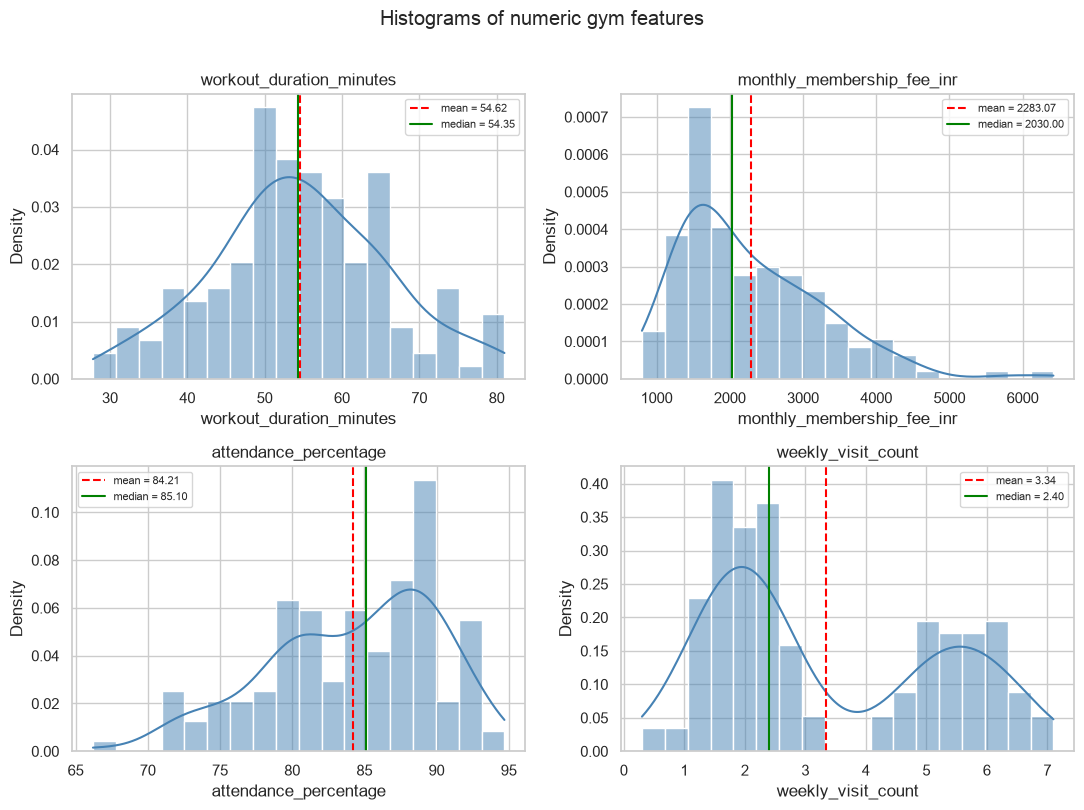

In [9]:
# Q9: 2x2 histogram grid with KDE, mean line, median line
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.ravel()

for ax, col in zip(axes, FEATURES):
    sns.histplot(df[col], kde=True, stat="density", ax=ax, bins=18, color="steelblue")
    m = df[col].mean()
    med = df[col].median()
    ax.axvline(m, color="red", linestyle="--", label=f"mean = {m:.2f}")
    ax.axvline(med, color="green", linestyle="-", label=f"median = {med:.2f}")
    ax.set_title(col)
    ax.legend(fontsize=8)

fig.suptitle("Histograms of numeric gym features", y=1.01)
plt.tight_layout()
plt.show()


### Q10

Does the histogram for the feature you predicted in Q8 confirm or contradict your prediction?
If your prediction was wrong, which feature actually turned out to be bimodal, and does the mean
computed in Q2 fall in a sensible place on that histogram, or does it fall in an empty "valley"?

**Your answer:**

The histogram confirms the prediction. `weekly_visit_count` has two peaks (around 2 visits and around 5-6 visits) with a gap between them. The Q2 mean (3.34) sits in that empty valley, so it is not a typical member.


### Q11  — Box plots

Standardize (z-score) the four numeric features — `z = (x - mean) / std` — and plot all four as **box plots side by side** on one figure, so their spreads are visually comparable despite being ondifferent original scales (₹, minutes, %, visits). Label the y-axis clearly. Briefly note in the plot title or a code comment which feature(s) show visible outlier points.

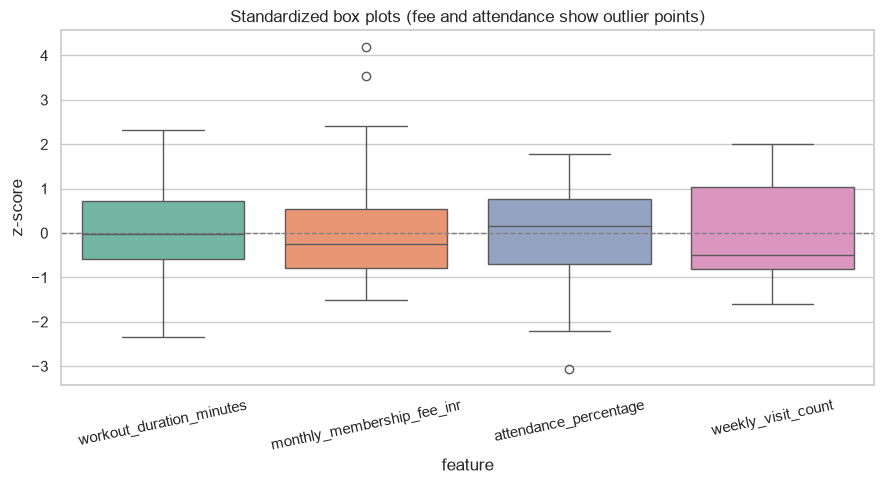

In [10]:
# Q11: z-score the four features and plot side-by-side box plots
z = (df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std(ddof=1)

plt.figure(figsize=(9, 5))
sns.boxplot(data=z, palette="Set2")
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.ylabel("z-score")
plt.xlabel("feature")
plt.xticks(rotation=12)
plt.title("Standardized box plots (fee and attendance show outlier points)")
plt.tight_layout()
plt.show()


### Q12 — Scatter plots

Choose **two pairs** of numeric features: one pair you hypothesize has a real relationship, and one
pair you hypothesize has little to no relationship. For each pair: compute the Pearson correlation
coefficient (`.corr()`), make a scatter plot, and put the correlation value in the plot title.

**Your answer (1–2 sentences per pair):** Did the scatter plots and correlation values support your
hypotheses? If a result surprised you, say so.

Pair 1 (`weekly_visit_count` vs `attendance_percentage`): I expected members who visit more often to also attend a higher share of scheduled sessions. The scatter slopes up and r = 0.52, so that holds.

Pair 2 (`workout_duration_minutes` vs `monthly_membership_fee_inr`): I did not expect session length to depend on how much someone pays. The plot is a cloud and r is about -0.02, so that also holds. No surprise.


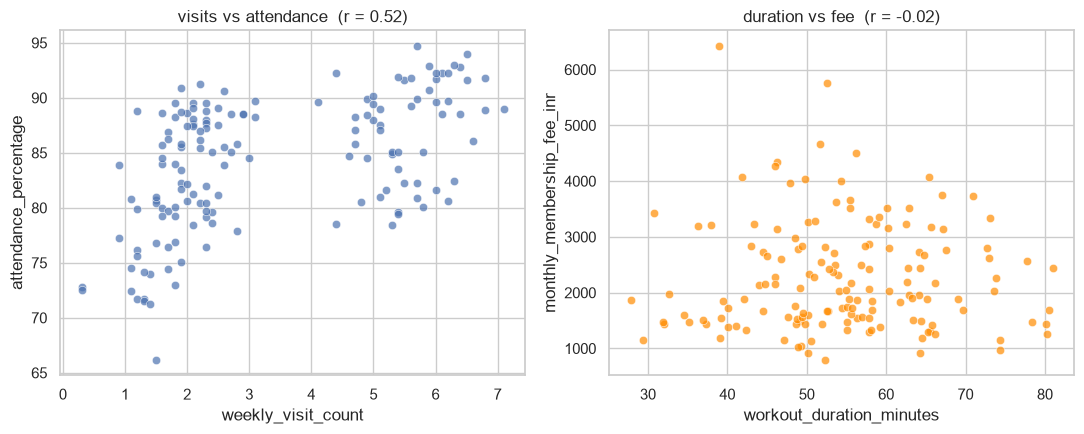

Pearson r (weekly_visit_count, attendance_percentage) = 0.521
Pearson r (workout_duration_minutes, monthly_membership_fee_inr) = -0.021


In [11]:
# Q12: one related pair, one unrelated pair
r_related = df["weekly_visit_count"].corr(df["attendance_percentage"])
r_unrelated = df["workout_duration_minutes"].corr(df["monthly_membership_fee_inr"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.scatterplot(
    data=df, x="weekly_visit_count", y="attendance_percentage",
    ax=axes[0], alpha=0.7,
)
axes[0].set_title(f"visits vs attendance  (r = {r_related:.2f})")

sns.scatterplot(
    data=df, x="workout_duration_minutes", y="monthly_membership_fee_inr",
    ax=axes[1], alpha=0.7, color="darkorange",
)
axes[1].set_title(f"duration vs fee  (r = {r_unrelated:.2f})")

plt.tight_layout()
plt.show()

print(f"Pearson r (weekly_visit_count, attendance_percentage) = {r_related:.3f}")
print(f"Pearson r (workout_duration_minutes, monthly_membership_fee_inr) = {r_unrelated:.3f}")


## Part 6 — Synthesis

### Q13 

Build **one summary table** with a row per numeric feature and columns for: mean, median, standard
deviation, IQR, skewness, and excess kurtosis (you have already computed all of these in Q2, Q5–Q7
— this question is about assembling them, not recomputing from scratch).

Then write a short paragraph (roughly 100–150 words) that, **for each of the four features**,
recommends which central-tendency measure (mean or median) and which dispersion measure (standard
deviation or IQR) should be reported, and briefly justifies the choice using the specific evidence
in your own table (not general rules quoted from Lab 3).

In [12]:
# Q13: assemble comparative summary from earlier tables
summary = pd.DataFrame({
    "mean": ct["mean"],
    "median": ct["median"],
    "std": df[FEATURES].std(ddof=1),
    "IQR": iqr_tbl["IQR"],
    "skewness": shape_tbl["skewness"],
    "excess_kurtosis": shape_tbl["excess_kurtosis"],
})
display(summary)


,mean,median,std,IQR,skewness,excess_kurtosis
workout_duration_minutes,54.618,54.35,11.397,14.825,0.081,-0.160
monthly_membership_fee_inr,2283.067,2030.00,984.837,1310.000,1.177,1.863
attendance_percentage,84.210,85.10,5.874,8.600,-0.561,-0.324
weekly_visit_count,3.337,2.40,1.886,3.500,0.446,-1.375


**Your answer (recommendation paragraph):**

`workout_duration_minutes` is nearly symmetric (skew 0.08) with no IQR outliers, so the mean (54.6 min) and standard deviation (11.4 min) are fair summaries. `monthly_membership_fee_inr` is right-skewed (skew 1.18) with two high outliers, so I would report the median (Rs 2030) and the IQR (Rs 1310) rather than the mean and std, which get pulled by the long tail. `attendance_percentage` is mildly left-skewed (skew -0.56) with one low outlier; the median (85.1%) and IQR (8.6 points) are safer than the mean. `weekly_visit_count` has the largest mean-median gap and a negative excess kurtosis (-1.38). The histogram is bimodal, and the mean (3.34) sits in the valley between the two groups, so the median (2.4 visits) and IQR (3.5) should be reported. Using the mean here would describe a visit rate that almost nobody actually has.


---

## Bonus (optional)

Group `df` by `preferred_workout` (`df.groupby("preferred_workout")`) and compare the mean
`attendance_percentage` across the four workout categories. Is attendance noticeably different for
any one category? Give one plausible real-world explanation for what you find (or for why there's
no real difference, if that's what you observe).

In [13]:
# Bonus: mean attendance by preferred_workout
att = (
    df.groupby("preferred_workout")["attendance_percentage"]
    .agg(["mean", "median", "count"])
    .sort_values("mean")
)
display(att)
print("Range of group means:", round(att["mean"].max() - att["mean"].min(), 2), "points")


,mean,median,count
preferred_workout,,,
CrossFit,82.325,80.5,16
Cardio,83.558,83.9,53
Yoga,84.029,85.3,28
Weights,85.526,87.3,53


Range of group means: 3.2 points


---

Mean attendance is close across the four workout types (Weights 85.5, Yoga 84.0, Cardio 83.6, CrossFit 82.3). The gap is only about 3 points, and CrossFit has just 16 members, so I would not treat this as a real attendance difference. If the small CrossFit dip is real at all, it could be because the sessions are high intensity and people take extra rest days.

### Before you submit
- [x] Ran the notebook top to bottom with no errors (Kernel → Restart & Run All)
- [x] Every `# TODO` cell has working code, not just comments
- [x] Every "Your answer" cell has a written response in your own words
- [x] Did not modify the Part 1 dataset-generation code or the random seed
